# 015 生成对抗网络：题目要求

**需要完成：** 完成噪声、判别器、生成器、稳定 BCE、LSGAN 损失及结构检查；训练普通 GAN、LSGAN、DCGAN；保存样本并回答比较问题。

**实验范围与验收：** 普通 GAN 与 LSGAN 各 10 轮，DCGAN 5 轮；复用已有 MNIST。原循环按训练采样器取 50000 张，跳过不足 128 张的尾批，每轮实际 49920 张。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。


# Generative Adversarial Networks (GANs)
到目前为止，在CS231N中，我们已经探索过的所有神经网络应用都是**判别模型**，它接受输入并训练生成标记输出。从简单的图像分类到句子生成(这仍然是一个分类问题，我们的标签在词汇空间中，我们学习了一个递归式来捕获多词标签)。在这个笔记本中，我们将扩展我们的repetoire算法，并使用神经网络构建生成模型。具体来说，我们将学习如何建立模型，产生新的即时通讯
### What is a GAN?

In 2014, [Goodfellow et al.](https://arxiv.org/abs/1406.2661) presented a method for training generative models called Generative Adversarial Networks (GANs for short). In a GAN, we build two different neural networks. Our first network is a traditional classification network, called the **discriminator**. We will train the discriminator to take images, and classify them as being real (belonging to the training set) or fake (not present in the training set). Our other network, called the **generator**, will take random noise as input and transform it using a neural network to produce images. The goal of the generator is to fool the discriminator into thinking the images it produced are real.

We can think of this back and forth process of the generator ($G$) trying to fool the discriminator ($D$), and the discriminator trying to correctly classify real vs. fake as a minimax game:
$$\underset{G}{\text{minimize}}\; \underset{D}{\text{maximize}}\; \mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$
where $z \sim p(z)$ are the random noise samples, $G(z)$ are the generated images using the neural network generator $G$, and $D$ is the output of the discriminator, specifying the probability of an input being real. In [Goodfellow et al.](https://arxiv.org/abs/1406.2661), they analyze this minimax game and show how it relates to minimizing the Jensen-Shannon divergence between the training data distribution and the generated samples from $G$.

To optimize this minimax game, we will aternate between taking gradient *descent* steps on the objective for $G$, and gradient *ascent* steps on the objective for $D$:
1. update the **generator** ($G$) to minimize the probability of the __discriminator making the correct choice__. 
2. update the **discriminator** ($D$) to maximize the probability of the __discriminator making the correct choice__.

While these updates are useful for analysis, they do not perform well in practice. Instead, we will use a different objective when we update the generator: maximize the probability of the **discriminator making the incorrect choice**. This small change helps to allevaiate problems with the generator gradient vanishing when the discriminator is confident. This is the standard update used in most GAN papers, and was used in the original paper from [Goodfellow et al.](https://arxiv.org/abs/1406.2661). 

In this assignment, we will alternate the following updates:
1. Update the generator ($G$) to maximize the probability of the discriminator making the incorrect choice on generated data:
$$\underset{G}{\text{maximize}}\;  \mathbb{E}_{z \sim p(z)}\left[\log D(G(z))\right]$$
2. Update the discriminator ($D$), to maximize the probability of the discriminator making the correct choice on real and generated data:
$$\underset{D}{\text{maximize}}\; \mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$

### What else is there?
Since 2014, GANs have exploded into a huge research area, with massive [workshops](https://sites.google.com/site/nips2016adversarial/), and [hundreds of new papers](https://github.com/hindupuravinash/the-gan-zoo). Compared to other approaches for generative models, they often produce the highest quality samples but are some of the most difficult and finicky models to train (see [this github repo](https://github.com/soumith/ganhacks) that contains a set of 17 hacks that are useful for getting models working). Improving the stabiilty and robustness of GAN training is an open research question, with new papers coming out every day! For a more recent tutorial on GANs, see [here](https://arxiv.org/abs/1701.00160). There is also some even more recent exciting work that changes the objective function to Wasserstein distance and yields much more stable results across model architectures: [WGAN](https://arxiv.org/abs/1701.07875), [WGAN-GP](https://arxiv.org/abs/1704.00028).


GANs are not the only way to train a generative model! For other approaches to generative modeling check out the [deep generative model chapter](http://www.deeplearningbook.org/contents/generative_models.html) of the Deep Learning [book](http://www.deeplearningbook.org). Another popular way of training neural networks as generative models is Variational Autoencoders (co-discovered [here](https://arxiv.org/abs/1312.6114) and [here](https://arxiv.org/abs/1401.4082)). Variatonal autoencoders combine neural networks with variationl inference to train deep generative models. These models tend to be far more stable and easier to train but currently don't produce samples that are as pretty as GANs.

Here's an example of what your outputs from the 3 different models you're going to train should look like... note that GANs are sometimes finicky, so your outputs might not look exactly like this... this is just meant to be a *rough* guideline of the kind of quality you can expect:

![caption](gan_outputs_pytorch.png)

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


## Setup

**本段解析**

导入 GAN 所需网络、优化器、Dataset 和显示工具，固定随机种子，读取课程损失参考数组。参考文件虽含 tf 命名，但只是 NumPy 数值资源，不安装或调用 TensorFlow。

In [2]:
import torch
torch.manual_seed(231)
torch.set_num_threads(4)
import torch.nn as nn
from torch.nn import init
from torch.autograd import Variable
import torchvision
import torchvision.transforms as T
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import sampler
import torchvision.datasets as dset

import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

def show_images(images):
    images = np.reshape(images, [images.shape[0], -1])  # images reshape to (batch_size, D)
    sqrtn = int(np.ceil(np.sqrt(images.shape[0])))
    sqrtimg = int(np.ceil(np.sqrt(images.shape[1])))

    fig = plt.figure(figsize=(sqrtn, sqrtn))
    gs = gridspec.GridSpec(sqrtn, sqrtn)
    gs.update(wspace=0.05, hspace=0.05)

    for i, img in enumerate(images):
        ax = plt.subplot(gs[i])
        plt.axis('off')
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_aspect('equal')
        plt.imshow(img.reshape([sqrtimg,sqrtimg]))
    return 

def preprocess_img(x):
    return 2 * x - 1.0

def deprocess_img(x):
    return (x + 1.0) / 2.0

def rel_error(x,y):
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def count_params(model):
    """Count the number of parameters in the current TensorFlow graph """
    param_count = np.sum([np.prod(p.size()) for p in model.parameters()])
    return param_count

answers = np.load('gan-checks-tf.npz')

## Dataset
GANs是出了名的讲究超参数，也需要很多的训练时间。为了让这项任务在没有GPU的情况下也可以完成，我们将使用MNIST数据集，它包含6万张训练图和1万张测试图。每张图片都包含一幅以白色数字为中心的图像，背景为黑色(0到9)。这是第一批用于训练卷积神经网络的数据集之一，非常简单——一个标准的CNN模型可以轻松地超过99%的准确率。

为了简化这里的代码，我们将使用PyTorch MNIST包装器，它下载并加载MNIST数据集

See the [documentation](https://github.com/pytorch/vision/blob/master/torchvision/datasets/mnist.py) for more information about the interface. The default parameters will take 5,000 of the training examples and place them into a validation dataset. The data will be saved into a folder called `MNIST_data`. 

**本段解析**

ChunkSampler 按连续索引定义训练/验证子集；ExistingMNIST 直接读取本机已有 gzip 到内存，不重复下载。图像转为 [0,1] 的单通道张量，训练判别器前再映射到 [−1,1]。

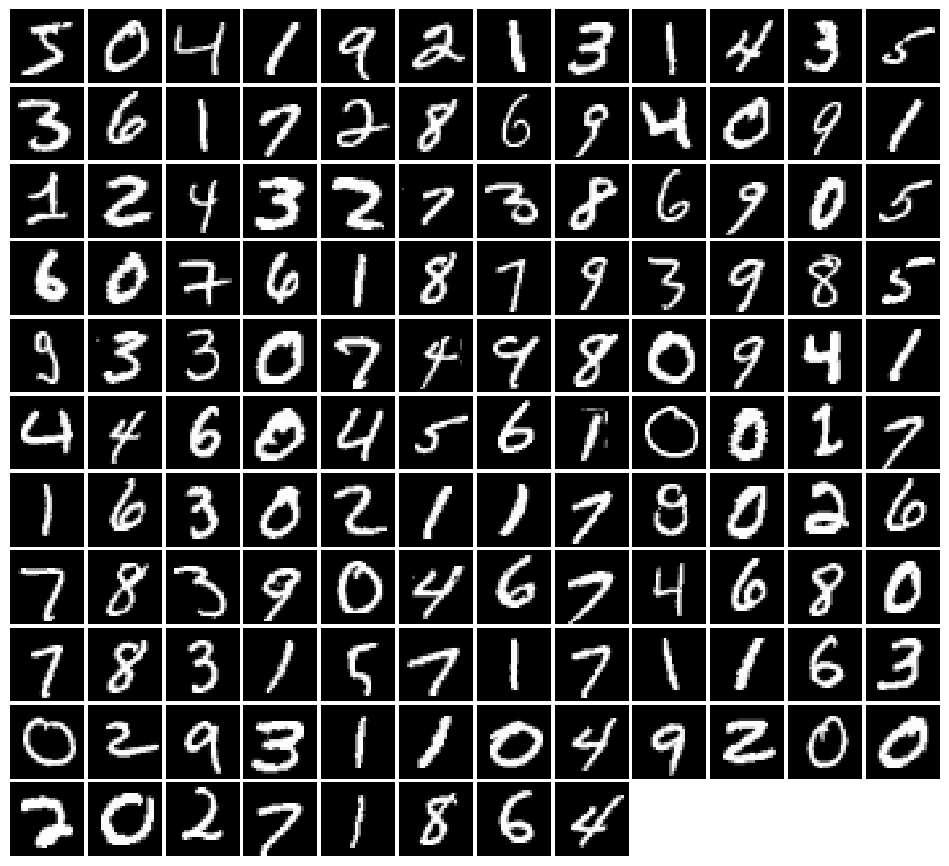

In [3]:
from study_runtime import ExistingMNIST
class ChunkSampler(sampler.Sampler):
    """Samples elements sequentially from some offset. 
    Arguments:
        num_samples: # of desired datapoints
        start: offset where we should start selecting from
    """
    def __init__(self, num_samples, start=0):
        self.num_samples = num_samples
        self.start = start

    def __iter__(self):
        return iter(range(self.start, self.start + self.num_samples))

    def __len__(self):
        return self.num_samples

NUM_TRAIN = 50000
NUM_VAL = 5000

NOISE_DIM = 96
batch_size = 128

mnist_train = ExistingMNIST('./cs231n/datasets/MNIST_data', train=True, download=False,
                           transform=T.ToTensor())
loader_train = DataLoader(mnist_train, batch_size=batch_size,
                          sampler=ChunkSampler(NUM_TRAIN, 0))

mnist_val = ExistingMNIST('./cs231n/datasets/MNIST_data', train=True, download=False,
                           transform=T.ToTensor())
loader_val = DataLoader(mnist_val, batch_size=batch_size,
                        sampler=ChunkSampler(NUM_VAL, NUM_TRAIN))


imgs = next(iter(loader_train))[0].view(batch_size, 784).numpy().squeeze()
show_images(imgs)

## 随机噪声
使用形状' [batch_size, dim] '从-1到1生成均匀的噪声。

Hint: use `torch.rand`.

**本段解析**

从 [−1,1] 均匀分布生成 (batch_size,dim) 噪声，每一行作为生成器的潜变量。噪声不包含真实数字标签，GAN 学习的是未条件化的图像分布。

In [4]:
def sample_noise(batch_size, dim):
    """
    Generate a PyTorch Tensor of uniform random noise.

    Input:
    - batch_size: Integer giving the batch size of noise to generate.
    - dim: Integer giving the dimension of noise to generate.
    
    Output:
    - A PyTorch Tensor of shape (batch_size, dim) containing uniform
      random noise in the range (-1, 1).
    """
    return torch.rand((batch_size,dim))*2-1


确保噪音是正确的形状和类型:

**本段解析**

固定种子检查噪声张量形状、范围和随机性。该测试验证输入接口，不能说明生成图像质量。

In [5]:
def test_sample_noise():
    batch_size = 3
    dim = 4
    torch.manual_seed(231)
    z = sample_noise(batch_size, dim)
    np_z = z.cpu().numpy()
    assert np_z.shape == (batch_size, dim)
    assert torch.is_tensor(z)
    assert np.all(np_z >= -1.0) and np.all(np_z <= 1.0)
    assert np.any(np_z < 0.0) and np.any(np_z > 0.0)
    print('All tests passed!')
    
test_sample_noise()

All tests passed!


## Flatten
回想一下我们以前的笔记本电脑中的Flatten操作…这一次我们还提供了一个Unflatten，您可能希望在实现卷积生成器时使用它。我们还提供了一个使用Xavier初始化而不是PyTorch的统一默认值的权值初始化器(并为您调用它)。

**本段解析**

定义展平、形状恢复、权重初始化和参数计数辅助模块。Flatten 保留 batch 维，恢复模块将生成向量转为 NCHW；初始化只在训练前执行，不能每次前向重置参数。

In [6]:
class Flatten(nn.Module):
    def forward(self, x):
        N, C, H, W = x.size() # read in N, C, H, W
        return x.view(N, -1)  # "flatten" the C * H * W values into a single vector per image
    
class Unflatten(nn.Module):
    """
    An Unflatten module receives an input of shape (N, C*H*W) and reshapes it
    to produce an output of shape (N, C, H, W).
    """
    def __init__(self, N=-1, C=128, H=7, W=7):
        super(Unflatten, self).__init__()
        self.N = N
        self.C = C
        self.H = H
        self.W = W
    def forward(self, x):
        return x.view(self.N, self.C, self.H, self.W)

def initialize_weights(m):
    if isinstance(m, nn.Linear) or isinstance(m, nn.ConvTranspose2d):
        init.xavier_uniform_(m.weight.data)

## CPU / GPU
By default all code will run on CPU. GPUs are not needed for this assignment, but will help you to train your models faster. If you do want to run the code on a GPU, then change the `dtype` variable in the following cell.

**本段解析**

选择本机 CUDA 浮点张量类型，确保生成器、判别器、真实图像和噪声在同一设备。GPU 可用性已经由真实卷积反向计算验证。

In [7]:
# dtype = torch.FloatTensor
dtype = torch.cuda.FloatTensor ## UNCOMMENT THIS LINE IF YOU'RE ON A GPU!


# 判别器
我们的第一步是建立一个鉴别器。作为“nn”的一部分填充架构。下面函数中的顺序构造函数。所有完全连接的层应该包括偏置项。架构是:
* 全连接层从784到256
* LeakyReLu为0.01
* 完全连接层从256到256
* LeakyReLu为0.01
* 完全连接层从256到1
 
Recall that the Leaky ReLU nonlinearity computes $f(x) = \max(\alpha x, x)$ for some fixed constant $\alpha$; for the LeakyReLU nonlinearities in the architecture above we set $\alpha=0.01$.
 
The output of the discriminator should have shape `[batch_size, 1]`, and contain real numbers corresponding to the scores that each of the `batch_size` inputs is a real image.

**本段解析**

构造全连接判别器，将 28×28 输入展平后经过 LeakyReLU 网络输出一个 logit。输出不先做 sigmoid，因为后面的稳定 BCE 直接接收 logits。

In [8]:
def discriminator():
    """
    Build and return a PyTorch model implementing the architecture above.
    """
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(784,256),
        nn.LeakyReLU(0.01),
        nn.Linear(256,256),
        nn.LeakyReLU(0.01),
        nn.Linear(256,1)   
    )
    return model

确认鉴别器参数数量正确的测试:

**本段解析**

检查判别器可训练参数总数是否等于题目规定值。这个结构检查可发现层宽、偏置或输入维数错误，但不能替代损失梯度检查和训练。

In [9]:
def test_discriminator(true_count=267009):
    model = discriminator()
    cur_count = count_params(model)
    if cur_count != true_count:
        print('Incorrect number of parameters in discriminator. Check your achitecture.')
    else:
        print('Correct number of parameters in discriminator.')     

test_discriminator()

Correct number of parameters in discriminator.


# 生成器
现在建设生成器网络:
* 全连接层，从noise - dim到1024
* ReLU
* 大小为1024的全连接层
* ReLU
* 大小为784的全连接层
* 双曲正切
 * 剪切图像为[-1,1]

**本段解析**

构造全连接生成器，把噪声逐层映射为 784 维图像，最后用 tanh 限定到 [−1,1]。输出范围必须与判别器真实图像预处理一致。

In [10]:
def generator(noise_dim=NOISE_DIM):
    """
    Build and return a PyTorch model implementing the architecture above.
    """
    model = nn.Sequential(
        nn.Linear(noise_dim,1024),
        nn.ReLU(),
        nn.Linear(1024,1024),
        nn.ReLU(),
        nn.Linear(1024,784),
        nn.Tanh()
    )
    return model

确认生成器参数数量正确的测试:

**本段解析**

使用指定噪声维度核对生成器参数数目，检查网络结构与题目一致。该数值只描述模型大小，不代表生成性能。

In [11]:
def test_generator(true_count=1858320):
    model = generator(4)
    cur_count = count_params(model)
    if cur_count != true_count:
        print('Incorrect number of parameters in generator. Check your achitecture.')
    else:
        print('Correct number of parameters in generator.')

test_generator()

Correct number of parameters in generator.


# GAN Loss

Compute the generator and discriminator loss. The generator loss is:
$$\ell_G  =  -\mathbb{E}_{z \sim p(z)}\left[\log D(G(z))\right]$$
and the discriminator loss is:
$$ \ell_D = -\mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] - \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$
Note that these are negated from the equations presented earlier as we will be *minimizing* these losses.

**HINTS**: You should use the `bce_loss` function defined below to compute the binary cross entropy loss which is needed to compute the log probability of the true label given the logits output from the discriminator. Given a score $s\in\mathbb{R}$ and a label $y\in\{0, 1\}$, the binary cross entropy loss is

$$ bce(s, y) = y * \log(s) + (1 - y) * \log(1 - s) $$

A naive implementation of this formula can be numerically unstable, so we have provided a numerically stable implementation for you below.

You will also need to compute labels corresponding to real or fake and use the logit arguments to determine their size. Make sure you cast these labels to the correct data type using the global `dtype` variable, for example:


`true_labels = Variable(torch.ones(size)).type(dtype)`

Instead of computing the expectation, we will be averaging over elements of the minibatch, so make sure to combine the loss by averaging instead of summing.

**本段解析**

使用稳定的 logits 形式计算二元交叉熵，避免先 sigmoid 后 log 带来的溢出或 log(0)。输入 logits 与 0/1 目标同形状，输出平均标量损失。

In [12]:
def bce_loss(input, target):
    """
    Numerically stable version of the binary cross-entropy loss function.

    As per https://github.com/pytorch/pytorch/issues/751
    See the TensorFlow docs for a derivation of this formula:
    https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits

    Inputs:
    - input: PyTorch Variable of shape (N, ) giving scores.
    - target: PyTorch Variable of shape (N,) containing 0 and 1 giving targets.

    Returns:
    - A PyTorch Variable containing the mean BCE loss over the minibatch of input data.
    """
    neg_abs = - input.abs()
    loss = input.clamp(min=0) - input * target + (1 + neg_abs.exp()).log()
    return loss.mean()

**本段解析**

定义判别器真实样本目标为 1、伪样本目标为 0 的损失，并定义生成器将伪样本推向目标 1 的非饱和损失。两者使用不同标签目标，更新时分别冻结对方所需的计算路径。

In [13]:
def discriminator_loss(logits_real, logits_fake):
    """
    Computes the discriminator loss described above.
    
    Inputs:
    - logits_real: PyTorch Variable of shape (N,) giving scores for the real data.
    - logits_fake: PyTorch Variable of shape (N,) giving scores for the fake data.
    
    Returns:
    - loss: PyTorch Variable containing (scalar) the loss for the discriminator.
    """
    real_labels = torch.ones_like(logits_real).type(dtype)
    fake_labels = 1-real_labels
    loss_dis =bce_loss(logits_real,real_labels)
    loss_gen =bce_loss(logits_fake,fake_labels)
    loss=loss_dis+loss_gen
    return loss

def generator_loss(logits_fake):
    """
    Computes the generator loss described above.

    Inputs:
    - logits_fake: PyTorch Variable of shape (N,) giving scores for the fake data.
    
    Returns:
    - loss: PyTorch Variable containing the (scalar) loss for the generator.
    """
    fake_labels = torch.ones_like(logits_fake).type(dtype)
    loss_gen =bce_loss(logits_fake,fake_labels)
    loss=loss_gen
    return loss

Test your generator and discriminator loss. You should see errors < 1e-7.

**本段解析**

把固定真实/伪 logits 送入判别器损失，与课程参考值比较。通过后才能进入对抗训练，否则即使有图像输出也可能优化了错误目标。

In [14]:
def test_discriminator_loss(logits_real, logits_fake, d_loss_true):
    d_loss = discriminator_loss(Variable(torch.Tensor(logits_real)).type(dtype),
                                Variable(torch.Tensor(logits_fake)).type(dtype)).data.cpu().numpy()
    print("Maximum error in d_loss: %g"%rel_error(d_loss_true, d_loss))

test_discriminator_loss(answers['logits_real'], answers['logits_fake'],
                        answers['d_loss_true'])

Maximum error in d_loss: 3.97058e-09

**本段解析**

单独检查生成器损失的参考值，确认非饱和目标和符号正确。生成器应该希望判别器把其输出判为真实，而不是帮助判别器识别伪样本。

In [15]:
def test_generator_loss(logits_fake, g_loss_true):
    g_loss = generator_loss(Variable(torch.Tensor(logits_fake)).type(dtype)).data.cpu().numpy()
    print("Maximum error in g_loss: %g"%rel_error(g_loss_true, g_loss))

test_generator_loss(answers['logits_fake'], answers['g_loss_true'])

Maximum error in g_loss: 4.4518e-09


# 优化我们的损失
创建一个返回' optim '的函数。Adam的优化器对于给定的模型具有1e-3的学习率，beta1=0.5, beta2=0.999。您将使用它来为生成器构造优化器，并为笔记本的其余部分构造鉴别器。

**本段解析**

给每个网络分别创建 Adam 优化器，学习率 1e-3，beta1=0.5，beta2=0.999。生成器与判别器不能共享同一个动量状态。

In [16]:
def get_optimizer(model):
    """
    Construct and return an Adam optimizer for the model with learning rate 1e-3,
    beta1=0.5, and beta2=0.999.
    
    Input:
    - model: A PyTorch model that we want to optimize.
    
    Returns:
    - An Adam optimizer for the model with the desired hyperparameters.
    """
    optimizer = optim.Adam(model.parameters(),betas=(0.5,0.999))
    return optimizer

# Training a GAN!

们为您提供主要的培训循环…您不需要更改这个函数，但是我们鼓励您通读并理解它

**本段解析**

每个 batch 先更新判别器：真实图像和 detach 后的生成图像分别得到 logits；再重新生成一批图像，保留生成器计算图更新生成器。记录两种损失并定期显示样本；原循环跳过不足 128 个样本的尾批，实际每轮覆盖量需在报告中说明。

In [17]:
def run_a_gan(D, G, D_solver, G_solver, discriminator_loss, generator_loss, show_every=250, 
              batch_size=128, noise_size=96, num_epochs=10):
    """
    Train a GAN!
    
    Inputs:
    - D, G: PyTorch models for the discriminator and generator
    - D_solver, G_solver: torch.optim Optimizers to use for training the
      discriminator and generator.
    - discriminator_loss, generator_loss: Functions to use for computing the generator and
      discriminator loss, respectively.
    - show_every: Show samples after every show_every iterations.
    - batch_size: Batch size to use for training.
    - noise_size: Dimension of the noise to use as input to the generator.
    - num_epochs: Number of epochs over the training dataset to use for training.
    """
    import time, json
    from study_runtime import ROOT
    run_id = getattr(run_a_gan, 'run_id', 0) + 1
    run_a_gan.run_id = run_id
    name = {1:'vanilla', 2:'lsgan', 3:'dcgan'}[run_id]
    folder = ROOT / 'outputs' / '015_GANs_PyTorch'
    checkpoint_dir = folder / 'checkpoints' / name
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    history = []
    started = time.perf_counter()
    iter_count = 0
    for epoch in range(num_epochs):
        for x, _ in loader_train:
            if len(x) != batch_size:
                continue
            D_solver.zero_grad()
            real_data = x.type(dtype)
            logits_real = D(2* (real_data - 0.5)).type(dtype)

            g_fake_seed = sample_noise(batch_size, noise_size).type(dtype)
            fake_images = G(g_fake_seed).detach()
            logits_fake = D(fake_images.view(batch_size, 1, 28, 28))

            d_total_error = discriminator_loss(logits_real, logits_fake)
            d_total_error.backward()        
            D_solver.step()

            G_solver.zero_grad()
            g_fake_seed = sample_noise(batch_size, noise_size).type(dtype)
            fake_images = G(g_fake_seed)

            gen_logits_fake = D(fake_images.view(batch_size, 1, 28, 28))
            g_error = generator_loss(gen_logits_fake)
            g_error.backward()
            G_solver.step()

            history.append({'epoch':epoch+1, 'step':iter_count+1,
                            'discriminator_loss':d_total_error.item(), 'generator_loss':g_error.item()})
            if (iter_count % show_every == 0):
                print('Iter: {}, D: {:.4}, G:{:.4}'.format(iter_count,d_total_error.item(),g_error.item()))
                imgs_numpy = fake_images.data.cpu().numpy()
                show_images(imgs_numpy[0:16])
                plt.show()
                print()
            iter_count += 1
        torch.save({'generator':G.state_dict(), 'discriminator':D.state_dict(),
                    'generator_optimizer':G_solver.state_dict(), 'discriminator_optimizer':D_solver.state_dict(),
                    'epoch':epoch+1, 'history':history, 'torch_rng':torch.get_rng_state(),
                    'cuda_rng':torch.cuda.get_rng_state()}, checkpoint_dir/'latest.pt')
        (folder/(name+'_history.json')).write_text(json.dumps(history), encoding='utf-8')
    report = {'epochs_completed':num_epochs, 'steps_completed':iter_count,
              'samples_per_epoch':(len(loader_train.sampler)//batch_size)*batch_size,
              'elapsed_seconds':time.perf_counter()-started,
              'generator_parameters':sum(p.numel() for p in G.parameters()),
              'discriminator_parameters':sum(p.numel() for p in D.parameters())}
    (folder/(name+'_report.json')).write_text(json.dumps(report,indent=2), encoding='utf-8')
    print(report)
    plt.figure(figsize=(10,4))
    plt.plot([r['discriminator_loss'] for r in history], label='Discriminator')
    plt.plot([r['generator_loss'] for r in history], label='Generator')
    plt.xlabel('Update step'); plt.ylabel('Loss'); plt.title(name); plt.legend(); plt.show()


这并不难，对吧?在低100s的迭代中，你应该看到黑色的背景，当你接近迭代1000时，模糊的形状，和象样的形状，当我们超过3000时，其中大约一半将是清晰可识别的。

**本段解析**

创建独立的原始 GAN 网络与优化器，按题目完成十轮训练。观察由噪声向数字轮廓演化的过程，同时保留模式坍塌或模糊样本，不能只选择好看的数字报告。

Iter: 0, D: 1.328, G:0.7202

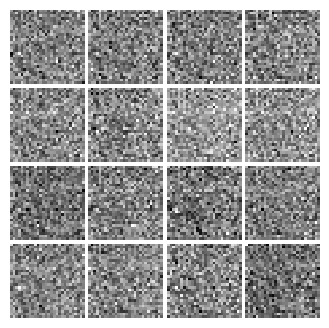

Iter: 250, D: 1.498, G:0.7223


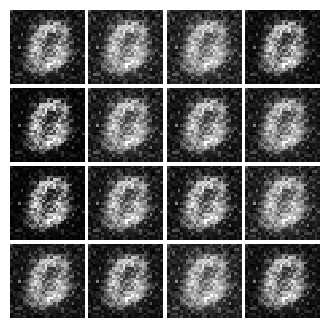

Iter: 500, D: 1.076, G:1.399


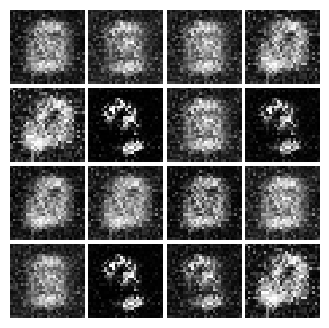

Iter: 750, D: 1.272, G:0.5179


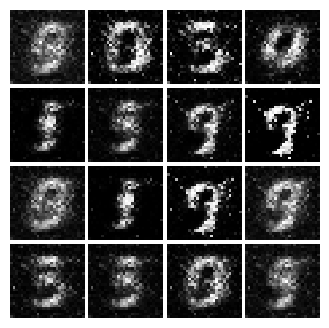

Iter: 1000, D: 1.247, G:1.093


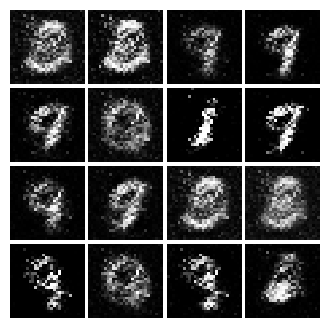

Iter: 1250, D: 1.266, G:1.372


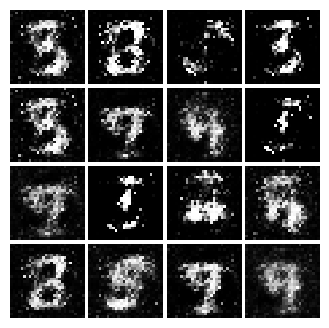

Iter: 1500, D: 1.301, G:1.636


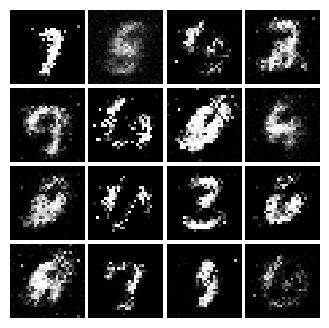

Iter: 1750, D: 1.318, G:0.9259


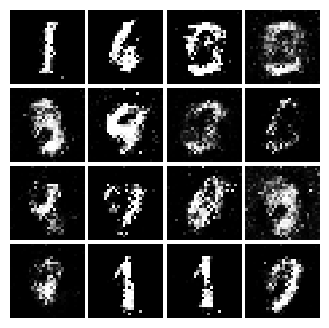

Iter: 2000, D: 1.407, G:1.012


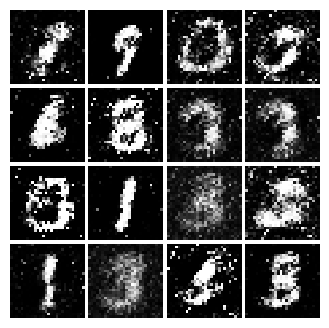

Iter: 2250, D: 1.45, G:0.833


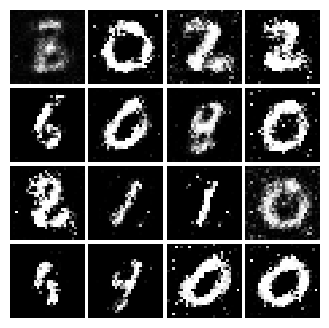

Iter: 2500, D: 1.324, G:0.7851


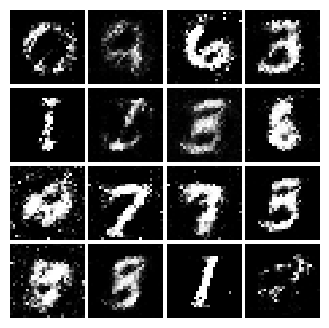

Iter: 2750, D: 1.302, G:0.8914


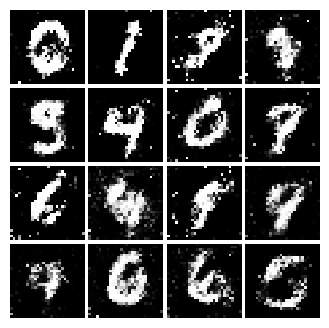

Iter: 3000, D: 1.326, G:0.7819


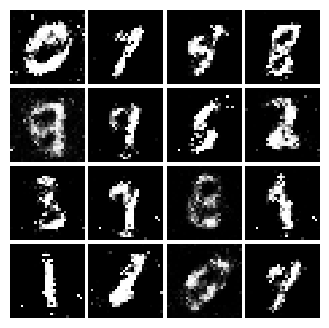

Iter: 3250, D: 1.279, G:0.7863


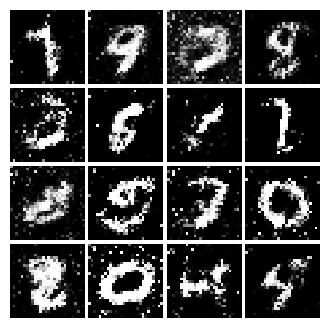

Iter: 3500, D: 1.327, G:0.9272


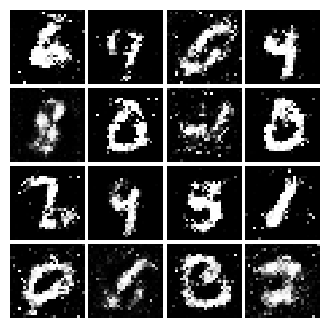

Iter: 3750, D: 1.209, G:1.071


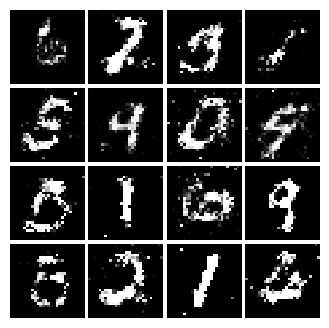

{'epochs_completed': 10, 'steps_completed': 3900, 'samples_per_epoch': 49920, 'elapsed_seconds': 35.657769800003734, 'generator_parameters': 1952528, 'discriminator_parameters': 267009}


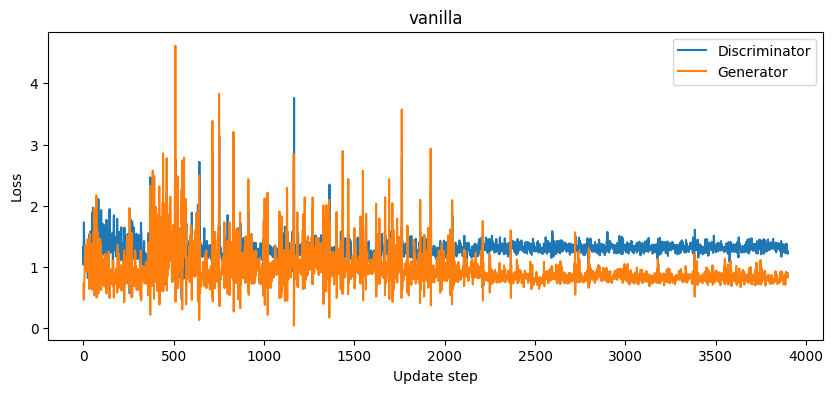

In [18]:
# Make the discriminator
D = discriminator().type(dtype)

# Make the generator
G = generator().type(dtype)

# Use the function you wrote earlier to get optimizers for the Discriminator and the Generator
D_solver = get_optimizer(D)
G_solver = get_optimizer(G)
# Run it!
run_a_gan(D, G, D_solver, G_solver, discriminator_loss, generator_loss)

# Least Squares GAN
We'll now look at [Least Squares GAN](https://arxiv.org/abs/1611.04076), a newer, more stable alernative to the original GAN loss function. For this part, all we have to do is change the loss function and retrain the model. We'll implement equation (9) in the paper, with the generator loss:
$$\ell_G  =  \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[\left(D(G(z))-1\right)^2\right]$$
and the discriminator loss:
$$ \ell_D = \frac{1}{2}\mathbb{E}_{x \sim p_\text{data}}\left[\left(D(x)-1\right)^2\right] + \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[ \left(D(G(z))\right)^2\right]$$


**HINTS**: Instead of computing the expectation, we will be averaging over elements of the minibatch, so make sure to combine the loss by averaging instead of summing. When plugging in for $D(x)$ and $D(G(z))$ use the direct output from the discriminator (`scores_real` and `scores_fake`).

**本段解析**

定义 LSGAN 的最小二乘目标，用判别得分到目标 0/1 的平方距离替代 BCE。这里是原题要求的另一种 GAN 损失，属于方法一实验范围，不标成新增方法二。

In [19]:
def ls_discriminator_loss(scores_real, scores_fake):
    """
    Compute the Least-Squares GAN loss for the discriminator.
    
    Inputs:
    - scores_real: PyTorch Variable of shape (N,) giving scores for the real data.
    - scores_fake: PyTorch Variable of shape (N,) giving scores for the fake data.
    
    Outputs:
    - loss: A PyTorch Variable containing the loss.
    """
    loss=0.5*(torch.pow(scores_real-1,2).mean()+torch.pow(scores_fake,2).mean())
    return loss

def ls_generator_loss(scores_fake):
    """
    Computes the Least-Squares GAN loss for the generator.
    
    Inputs:
    - scores_fake: PyTorch Variable of shape (N,) giving scores for the fake data.
    
    Outputs:
    - loss: A PyTorch Variable containing the loss.
    """
    loss = 0.5*torch.pow(scores_fake-1,2).mean()
    return loss

在运行一个GANs与我们的新损失功能，让我们检查一下:

**本段解析**

将固定得分代入 LSGAN 判别器及生成器损失，对照两个参考值。检查 0.5 系数、真实/伪标签和 batch 平均方式一致。

In [20]:
def test_lsgan_loss(score_real, score_fake, d_loss_true, g_loss_true):
    score_real = torch.Tensor(score_real).type(dtype)
    score_fake = torch.Tensor(score_fake).type(dtype)
    d_loss = ls_discriminator_loss(score_real, score_fake).cpu().numpy()
    g_loss = ls_generator_loss(score_fake).cpu().numpy()
    print("Maximum error in d_loss: %g"%rel_error(d_loss_true, d_loss))
    print("Maximum error in g_loss: %g"%rel_error(g_loss_true, g_loss))

test_lsgan_loss(answers['logits_real'], answers['logits_fake'],
                answers['d_loss_lsgan_true'], answers['g_loss_lsgan_true'])

Maximum error in d_loss: 1.53171e-08
Maximum error in g_loss: 2.7837e-09


**本段解析**

为 LSGAN 新建全连接生成器、判别器和优化器，训练十轮。它与普通 GAN 不共享训练状态，才能比较损失形式变化后的实际生成现象。

Iter: 0, D: 0.5689, G:0.51


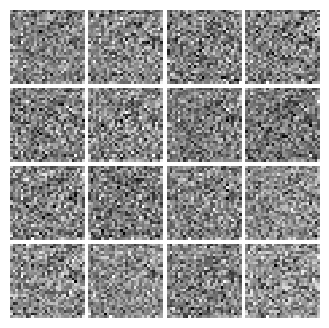

Iter: 250, D: 0.1804, G:0.4402


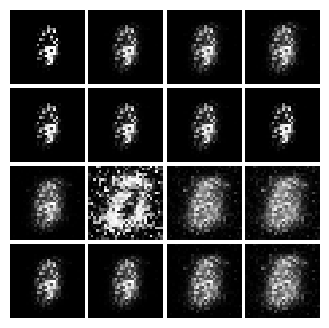

Iter: 500, D: 0.1495, G:0.4942


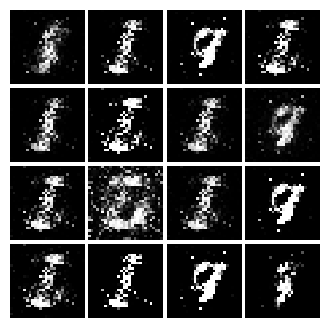

Iter: 750, D: 0.2101, G:0.2864


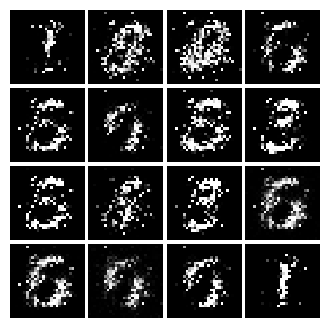

Iter: 1000, D: 0.199, G:0.261


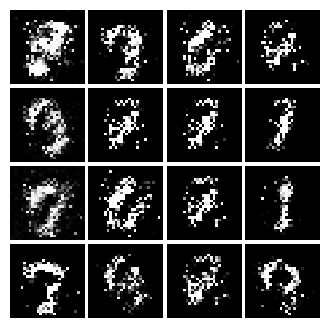

Iter: 1250, D: 0.2114, G:0.3644


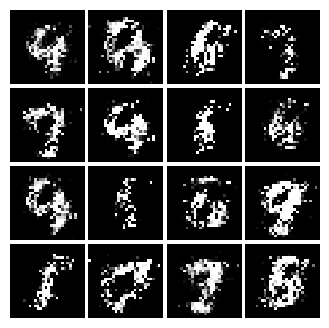

Iter: 1500, D: 0.1472, G:0.3064


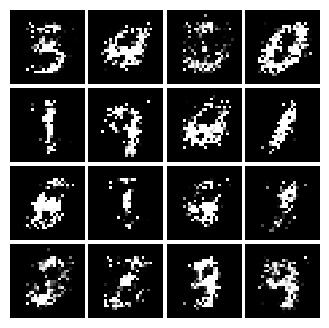

Iter: 1750, D: 0.1636, G:0.2573


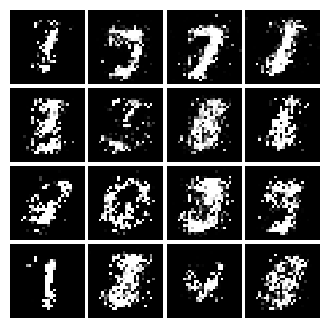

Iter: 2000, D: 0.2189, G:0.2102


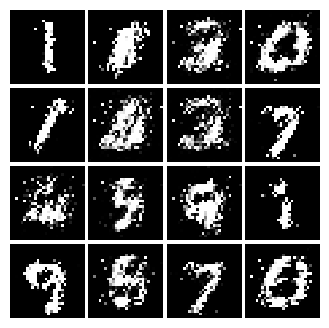

Iter: 2250, D: 0.1937, G:0.2826


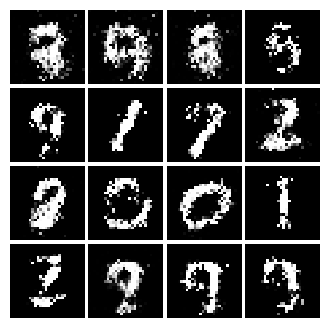

Iter: 2500, D: 0.2183, G:0.2175


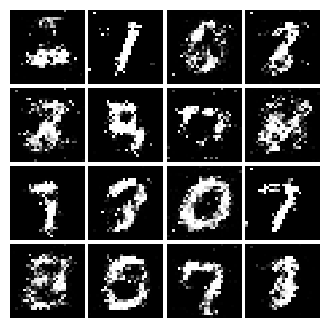

Iter: 2750, D: 0.2273, G:0.1636


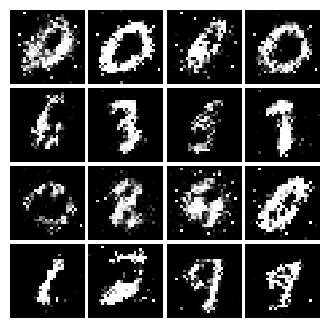

Iter: 3000, D: 0.2559, G:0.1651


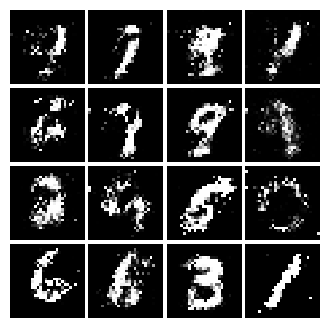

Iter: 3250, D: 0.2446, G:0.1713


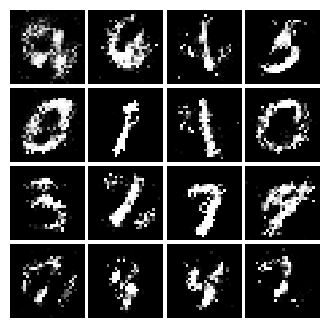

Iter: 3500, D: 0.222, G:0.1664


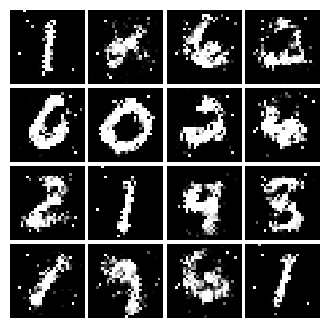

Iter: 3750, D: 0.2417, G:0.1576


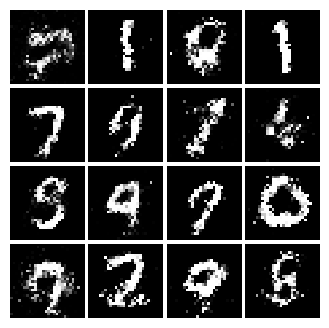

{'epochs_completed': 10, 'steps_completed': 3900, 'samples_per_epoch': 49920, 'elapsed_seconds': 33.820664800005034, 'generator_parameters': 1952528, 'discriminator_parameters': 267009}


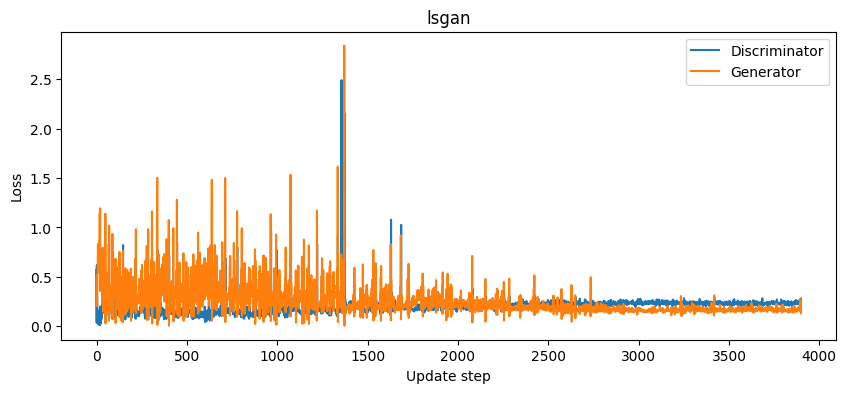

In [21]:
D_LS = discriminator().type(dtype)
G_LS = generator().type(dtype)

D_LS_solver = get_optimizer(D_LS)
G_LS_solver = get_optimizer(G_LS)

run_a_gan(D_LS, G_LS, D_LS_solver, G_LS_solver, ls_discriminator_loss, ls_generator_loss)

# INLINE QUESTION 1
Describe how the visual quality of the samples changes over the course of training. Do you notice anything about the distribution of the samples? How do the results change across different training runs?

## 我的观察

训练初期的生成样本主要是无结构噪声，随后出现黑色背景和白色笔画，后期可以辨认出多种数字形态。普通 GAN 与 LSGAN 的最终样本网格仍有断裂、散点和不完整轮廓，部分样本难以确定类别。展示的 16 张图不能证明十类分布均匀，也不能排除模式坍塌；需要更大样本及额外指标才能判断覆盖程度。

本次保留固定种子的一轮完整实验，没有伪称重复多个种子。不同初始化、噪声和对抗更新轨迹通常会影响结果，但跨次运行的波动未在本次作统计量化。LSGAN 是原题实验的一部分，不是新增改进方法。

# Deeply Convolutional GANs
In the first part of the notebook, we implemented an almost direct copy of the original GAN network from Ian Goodfellow. However, this network architecture allows no real spatial reasoning. It is unable to reason about things like "sharp edges" in general because it lacks any convolutional layers. Thus, in this section, we will implement some of the ideas from [DCGAN](https://arxiv.org/abs/1511.06434), where we use convolutional networks 

#### Discriminator
We will use a discriminator inspired by the TensorFlow MNIST classification tutorial, which is able to get above 99% accuracy on the MNIST dataset fairly quickly. 
* Reshape into image tensor (Use Unflatten!)
* 32 Filters, 5x5, Stride 1, Leaky ReLU(alpha=0.01)
* Max Pool 2x2, Stride 2
* 64 Filters, 5x5, Stride 1, Leaky ReLU(alpha=0.01)
* Max Pool 2x2, Stride 2
* Flatten
* Fully Connected size 4 x 4 x 64, Leaky ReLU(alpha=0.01)
* Fully Connected size 1

**本段解析**

构建卷积判别器，通过卷积、LeakyReLU、池化与全连接输出真假 logit。卷积利用图像局部结构，展平尺寸必须根据前面层的空间输出推导。

In [22]:
def build_dc_classifier():
    """
    Build and return a PyTorch model for the DCGAN discriminator implementing
    the architecture above.
    """
    return nn.Sequential(
        ###########################
        ######### TO DO ###########
        ###########################
        Unflatten(batch_size, 1, 28, 28),
        nn.Conv2d(1,32,5),
        nn.LeakyReLU(0.01),
        nn.MaxPool2d(2),
        nn.Conv2d(32,64,5),
        nn.LeakyReLU(0.01),
        nn.MaxPool2d(2),
        Flatten(),
        nn.Linear(4*4*64,4*4*64),
        nn.LeakyReLU(0.01),
        nn.Linear(4*4*64,1)
    )

data = Variable(next(iter(loader_train))[0]).type(dtype)
b = build_dc_classifier().type(dtype)
out = b(data)
print(out.size())

torch.Size([128, 1])


检查你的分类器参数的数量作为一个健全的检查:

**本段解析**

核对卷积判别器参数总数，发现通道数、核大小或全连接输入维度的偏差。输出检查通过后再用于 DCGAN。

In [23]:
def test_dc_classifer(true_count=1102721):
    model = build_dc_classifier()
    cur_count = count_params(model)
    if cur_count != true_count:
        print('Incorrect number of parameters in generator. Check your achitecture.')
    else:
        print('Correct number of parameters in generator.')

test_dc_classifer()

Correct number of parameters in generator.


#### Generator
For the generator, we will copy the architecture exactly from the [InfoGAN paper](https://arxiv.org/pdf/1606.03657.pdf). See Appendix C.1 MNIST. See the documentation for [tf.nn.conv2d_transpose](https://www.tensorflow.org/api_docs/python/tf/nn/conv2d_transpose). We are always "training" in GAN mode. 
* Fully connected of size 1024, ReLU
* BatchNorm
* Fully connected of size 7 x 7 x 128, ReLU
* BatchNorm
* Reshape into Image Tensor
* 64 conv2d^T filters of 4x4, stride 2, 'same' padding, ReLU
* BatchNorm
* 1 conv2d^T filter of 4x4, stride 2, 'same' padding, TanH
* Should have a 28x28x1 image, reshape back into 784 vector

**本段解析**

构建 DCGAN 生成器，先将潜变量映射到低分辨率特征，再用转置卷积逐步上采样，配合 BN/ReLU，最终 tanh 输出图像。转置卷积的输出尺寸由 stride、padding 和 kernel 共同决定。

In [24]:
def build_dc_generator(noise_dim=NOISE_DIM):
    """
    Build and return a PyTorch model implementing the DCGAN generator using
    the architecture described above.
    """
    return nn.Sequential(
        
        ###########################
        ######### TO DO ###########
        ###########################
        nn.Linear(noise_dim,1024),
        nn.ReLU(),
        nn.BatchNorm1d(1024),
        nn.Linear(1024,7*7*128),
        nn.ReLU(),
        nn.BatchNorm1d(7*7*128),
        Unflatten(batch_size,128,7,7),
        nn.ConvTranspose2d(128,64,4,2,1),
        nn.ReLU(),
        nn.BatchNorm2d(64),
        nn.ConvTranspose2d(64,1,4,2,1),
        nn.Tanh(),
        Flatten()     
    )

test_g_gan = build_dc_generator().type(dtype)
test_g_gan.apply(initialize_weights)

fake_seed = Variable(torch.randn(batch_size, NOISE_DIM)).type(dtype)
fake_images = test_g_gan.forward(fake_seed)
fake_images.size()

torch.Size([128, 784])

Check the number of parameters in your generator as a sanity check:

**本段解析**

核对卷积生成器参数数量，并用随机噪声检查输出尺寸和图像网格。此时图像来自未训练网络，不能作为完成训练的生成结果。

In [25]:
def test_dc_generator(true_count=6580801):
    model = build_dc_generator(4)
    cur_count = count_params(model)
    if cur_count != true_count:
        print('Incorrect number of parameters in generator. Check your achitecture.')
    else:
        print('Correct number of parameters in generator.')

test_dc_generator()

Correct number of parameters in generator.


**本段解析**

初始化 DCGAN 的两套网络与各自 Adam 状态，完成题目指定五轮训练。保存生成样本和损失，结合普通 GAN、LSGAN 的结果讨论质量与稳定性；三者预算不同，不能只凭最终图片作公平收敛速度结论。

Iter: 0, D: 1.37, G:1.492


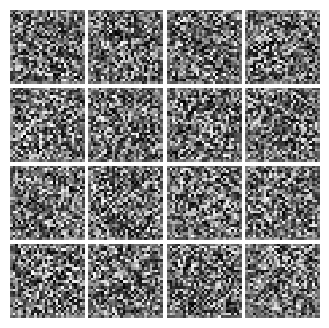

Iter: 250, D: 1.264, G:1.107


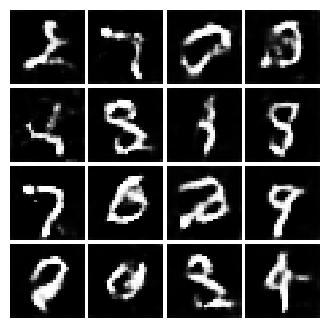

Iter: 500, D: 1.229, G:1.029


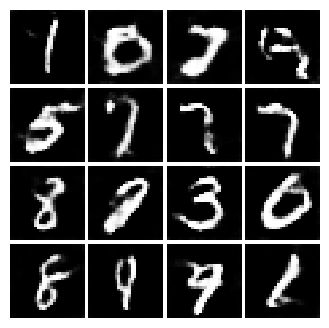

Iter: 750, D: 1.151, G:1.065


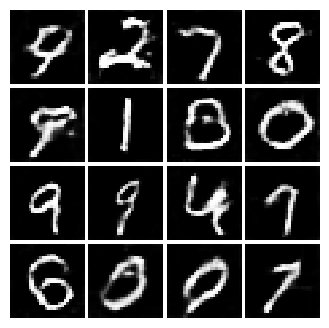

Iter: 1000, D: 1.185, G:0.957


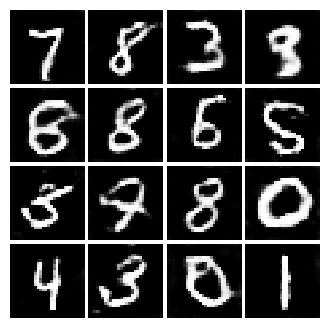

Iter: 1250, D: 1.207, G:0.9893


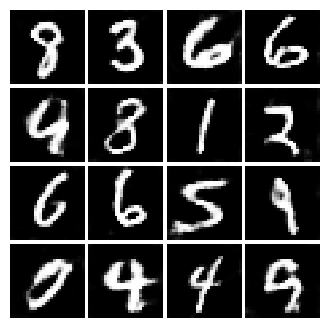

Iter: 1500, D: 1.069, G:1.086


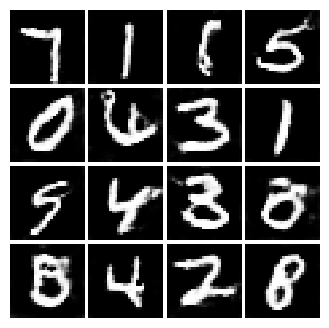

Iter: 1750, D: 1.071, G:1.136


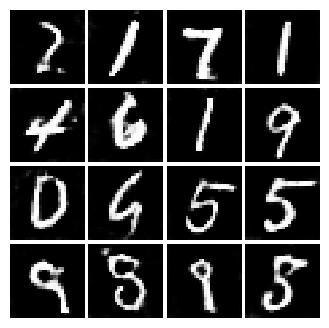

{'epochs_completed': 5, 'steps_completed': 1950, 'samples_per_epoch': 49920, 'elapsed_seconds': 29.220294200000353, 'generator_parameters': 6675009, 'discriminator_parameters': 1102721}


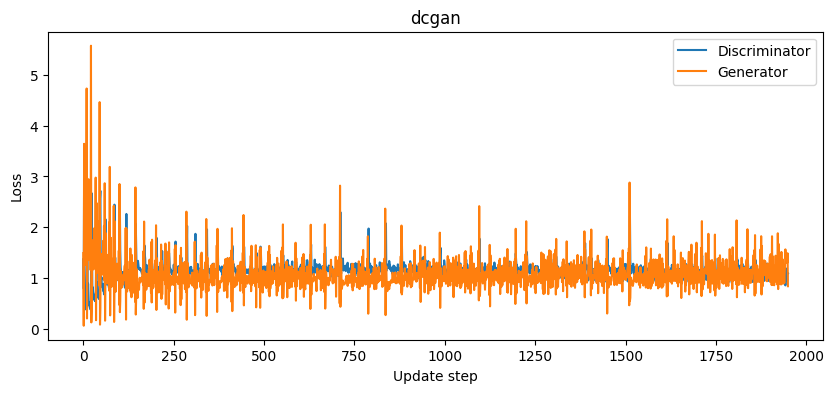

In [26]:
D_DC = build_dc_classifier().type(dtype) 
D_DC.apply(initialize_weights)
G_DC = build_dc_generator().type(dtype)
G_DC.apply(initialize_weights)

D_DC_solver = get_optimizer(D_DC)
G_DC_solver = get_optimizer(G_DC)

run_a_gan(D_DC, G_DC, D_DC_solver, G_DC_solver, discriminator_loss, generator_loss, num_epochs=5)

# INLINE QUESTION 2
What differences do you see between the DCGAN results and the original GAN results?

## 我的观察

本次 DCGAN 在五轮后的样本网格中，笔画比原全连接 GAN 更连贯，背景散点更少，多个数字可以清楚辨认；普通 GAN 与 LSGAN 的网格仍有较多碎裂轮廓。这与卷积结构利用局部空间模式的设计相符，但这里没有计算 FID 或数字识别器评分，所以只作当前样例的定性结论。

DCGAN 为五轮，前两种为十轮，结构、参数量与计算成本也不同，因此不能把最后一张图直接当作严格的等预算性能排名。三组完整训练记录、损失曲线和中间样本均保留，避免只展示成功图片。

## 额外学分
**确保你没有破坏你的结果以上，但自由复制+粘贴代码得到结果以下**
* 对于少量的额外积分，你可以在下面实现额外的新氮损失函数，前提是它们是收敛的。见AFI、BiGAN、Softmax GAN、Conditional GAN、InfoGAN等。
* 同样适用于改进的架构或使用卷积GAN(甚至实现VAE)
* 为了获得更大的额外学分，加载CIFAR10数据(见最后的作业)，并在CIFAR-10上训练一个引人注目的生成模型
* 新事物/酷。
#### Describe what you did here
**TBD**

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

In [27]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '015_GANs_PyTorch')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际问题。** 修正了 MNIST 数据集别名遗漏与迭代器 next 接口，冗余下载已从活跃目录归档，三种 GAN 均重跑完成。

**训练协议。** 原采样器取 50000 张，batch size 128 且跳过尾批，所以每轮实际 49920 张；不是完整 60000 张 MNIST 训练集。

**结果与方法选择。** DCGAN 的当前样本更清晰，但三组预算和结构不同，没有计算 FID。LSGAN/DCGAN 是原题内容，不伪称新提出的方法；保留模糊和不完整数字，避免只挑成功样例。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。